In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# unconditional EMT-TF step. Load signatures (has pseudotime + house layout).
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 1379 | pseudotime 0.0 -> 12.52


In [4]:
# score a WIDE EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX mesenchymal families; VIM excluded - a
# mesenchymal marker, not a TF). Gate on detectable expression; classify each by pseudotime end.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x = X[:,j]; expr = x>0; rho,_ = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(origin)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
# body/origin factor = least terminal (min rho); terminus factor = most terminal (max rho)
body_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
n_early = int((ok.end=='EARLY(origin)').sum())
print(f'\nexpressed EMT-TFs (frac>3%): {len(ok)}; classified EARLY(origin): {n_early}')
print(f'origin/body factor (min rho) = {body_tf}; terminus factor (max rho) = {terminus_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX2      0.003       0.007      0.010     0.022 LATE(terminus)
 FOXC2      0.003       0.000      0.011     0.073 LATE(terminus)
TWIST2      0.026       0.034      0.144     0.102 LATE(terminus)
TWIST1      0.109       0.222      0.288     0.104 LATE(terminus)
 FOXC1      0.069       0.056      0.216     0.166 LATE(terminus)
 PRRX1      0.068       0.087      0.228     0.171 LATE(terminus)
  ZEB2      0.763       2.015      3.001     0.192 LATE(terminus)
 SNAI2      0.407       1.306      2.772     0.223 LATE(terminus)
 SNAI1      0.094       0.088      0.498     0.234 LATE(terminus)
  ZEB1      0.126       0.109      0.534     0.240 LATE(terminus)

expressed EMT-TFs (frac>3%): 7; classified EARLY(origin): 0
origin/body factor (min rho) = TWIST1; terminus factor (max rho) = ZEB1


overlay thresholds (upper quartile among expressers): {'TWIST1': 3.17, 'ZEB1': 3.23} | cells shown: {'TWIST1': 38, 'ZEB1': 44}
TWIST1: 10.9% expressing; 38 shown; mean pseudotime of shown = 0.42
ZEB1: 12.6% expressing; 44 shown; mean pseudotime of shown = 0.73
saved expression.pdf


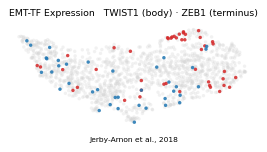

In [5]:
# categorical overlay: thresholded expressers of the two chosen TFs on a grey manifold (reference style)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [body_tf, terminus_tf]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [body_tf, terminus_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],2) for g in thr},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order = sorted([body_tf, terminus_tf], key=lambda g: -int(sel[g].sum()))
colors = {body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (body) \u00b7 {terminus_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Jerby-Arnon et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [body_tf, terminus_tf]:
    m = sel[g]
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f}')
print('saved expression.pdf')